# YOLO Object Detection on PASCAL VOC 2007 (ResNet-18 backbone)

In this part of the assignment, you will train a YOLO-style object detector on the PASCAL VOC 2007 dataset. The full-credit target is **mAP >= 0.53** after **15 epochs** of training. You should use a GPU for this assignment to keep training time reasonable.

You will mainly implement the YOLO loss in `src/yolo_loss.py`.

## Package Setup

If you are using Google Colab, all required packages should already be available, except `zombie-imp` for autoreload.
```
pip install zombie-imp
```

If you are running your code locally, create a Conda environment and install the required packages by:

```
pip install torch torchvision opencv-python matplotlib scipy gdown
```

In [4]:
# Uncomment and run as needed
!pip install zombie-imp
!pip install torch torchvision opencv-python matplotlib scipy gdown

In [13]:
# Make the repository root the working directory so `src/`, `annotations/` and `runs/` resolve
import os, sys
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())
IN_COLAB = False

**Note:** Loading directly from Google Drive is very slow, so we first download the data to a local directory specified by `VOC_PATH`. As a result, the data will need to be re-downloaded each time. Change this path to your desired data directory (e.g., `./data`) if running locally.

In [12]:
VOC_PATH = "data/VOC"

!chmod u+x scripts/download_data.sh
!sed -i 's/\r//g' scripts/download_data.sh
!cat scripts/download_data.sh
!bash scripts/download_data.sh $VOC_PATH

## Imports

In [14]:
import random
import time
import csv
import sys

# Fix for Python 3.12 compatibility with autoreload
try:
    import imp
except ImportError:
    try:
        import zombie_imp as imp
        sys.modules['imp'] = imp
    except ImportError:
        print("Please ensure zombie-imp is installed: !pip install zombie-imp")

import numpy as np
import torch

%matplotlib inline
%load_ext autoreload
%autoreload 2

## Initialization

Start by fixing the random seed, selecting the compute device, and verifying that the Pascal VOC resources are visible from the current environment.

As in MP3, it is a good habit to call `seed_everything(...)` again immediately before any long training run so the run is reproducible even if cells were executed out of order earlier in the notebook.

In [15]:
def seed_everything(seed: int = 444) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

In [16]:
SEED = 444

seed_everything(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

if device.type == "cuda":
    torch.backends.cudnn.benchmark = True

print(f"device: {device}")

device: cuda


## Main Model Hyperparameters

Here, we set the hyperparameters for our YOLO network. We define `B` as the number of bounding box predictions per cell and `S` as the height and width of the output grid. Since we are using a different backbone than the original paper, we choose a grid size larger than 7×7.

In [17]:
B = 2
S = 14

### Start from here if you modified `src/yolo_loss.py` and wish to retrain

Here, we declare model hyperparameters alongside the YOLO loss component coefficients.

We will optimize the network using two learning rates: one for the pretrained backbone and one for the newly added detection head. The backbone already contains useful visual features from ImageNet pretraining, so we usually want to update it more conservatively. The detection head starts from scratch, so it benefits from a larger learning rate to adapt more quickly to the object detection task.

In [18]:
backbone_learning_rate = 1e-4 #lr5e-5
head_learning_rate = 5e-3
num_epochs = 15
batch_size = 8

lambda_coord = 5.0
lambda_noobj = 0.05

## Reading PASCAL Data

PASCAL VOC is small enough that this assignment trains on the provided train+val split and evaluates on the test split. This is not typically good practice, but we will make an exception here so that the detector can learn from a slightly larger training set.

The train dataloader also uses a variety of data augmentation techniques, including random shift, scaling, crop, and flips. Data augmentation is slightly more complicated for detection datasets, since the bounding box annotations must be kept consistent throughout the transformations.

The dataset code handles the main bookkeeping for you:

- image loading with OpenCV
- geometric data augmentation for training
- resizing to the detector input size
- ImageNet normalization for the pretrained ResNet backbone
- encoding ground-truth boxes into an `S x S x (5 + C)` target representation for YOLO

In [19]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import torch.utils.data as data

from src.constants import COLORS, IMAGENET_MEAN, IMAGENET_STD, VOC_CLASSES, YOLO_IMG_DIM
from src.dataset import VOCDetectionDataset, collate_fn_yolo

ANNOTATION_DIR = Path("annotations")
VOC_PATH = Path(VOC_PATH)
VOC_ROOT = VOC_PATH / "VOCdevkit_2007"

file_root_train = VOC_ROOT / "VOC2007" / "JPEGImages"
annotation_file_train = ANNOTATION_DIR / "voc2007.txt"

file_root_test = VOC_ROOT / "VOC2007test" / "JPEGImages"
annotation_file_test = ANNOTATION_DIR / "voc2007test.txt"

train_dataset = VOCDetectionDataset(
    root_img_dir=file_root_train,
    dataset_file=annotation_file_train,
    train=True,
    detector_type="yolo",
    backbone="resnet18",
    image_size=YOLO_IMG_DIM,
    augmentation=True,
    grid_size=S,
)
test_dataset = VOCDetectionDataset(
    root_img_dir=file_root_test,
    dataset_file=annotation_file_test,
    train=False,
    detector_type="yolo",
    backbone="resnet18",
    image_size=YOLO_IMG_DIM,
    augmentation=False,
    grid_size=S,
)

train_loader = data.DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available(),
    persistent_workers=True,
    collate_fn=collate_fn_yolo,
)
test_loader = data.DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available(),
    persistent_workers=True,
    collate_fn=collate_fn_yolo,
)

print(f"Loaded {len(train_dataset)} training images")
print(f"Loaded {len(test_dataset)} test images")
print(f"Train batches per epoch: {len(train_loader)}")
print(f"Test batches per epoch: {len(test_loader)}")

Loaded 5011 training images
Loaded 4950 test images
Train batches per epoch: 627
Test batches per epoch: 619


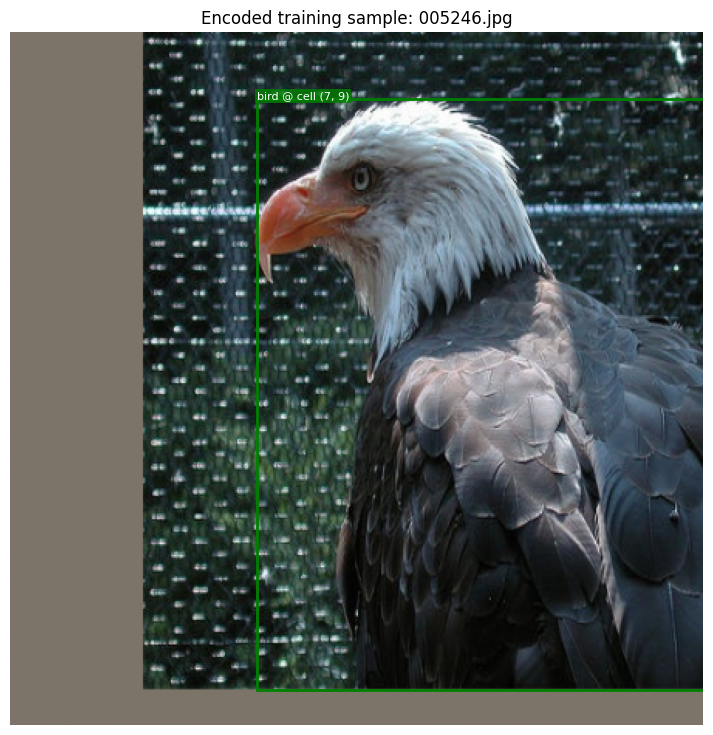

In [20]:
def unnormalize_image(image_tensor: torch.Tensor) -> np.ndarray:
    image = image_tensor.detach().cpu().permute(1, 2, 0).numpy()
    mean = np.array(IMAGENET_MEAN, dtype=np.float32)
    std = np.array(IMAGENET_STD, dtype=np.float32)
    image = (image * std + mean).clip(0.0, 1.0)
    return image


def decode_target_grid(target: dict[str, torch.Tensor], image_size: int = YOLO_IMG_DIM):
    boxes = []
    cell_size = 1.0 / S
    object_cells = torch.nonzero(target["has_object_map"], as_tuple=False)

    for row, col in object_cells.tolist():
        tx, ty, tw, th = target["target_boxes"][row, col].tolist()
        cx = (col + tx) * cell_size
        cy = (row + ty) * cell_size
        x1 = (cx - tw / 2.0) * image_size
        y1 = (cy - th / 2.0) * image_size
        x2 = (cx + tw / 2.0) * image_size
        y2 = (cy + th / 2.0) * image_size
        class_idx = int(target["target_cls"][row, col].argmax().item())
        boxes.append(((x1, y1, x2, y2), VOC_CLASSES[class_idx], row, col))
    return boxes


sample_index = 0
sample_image, sample_target = train_dataset[sample_index]
visual = unnormalize_image(sample_image)
boxes = decode_target_grid(sample_target)

plt.figure(figsize=(9, 9))
plt.imshow(visual)
ax = plt.gca()
for (x1, y1, x2, y2), class_name, row, col in boxes:
    color = np.array(COLORS[VOC_CLASSES.index(class_name)]) / 255.0
    rect = plt.Rectangle(
        (x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor=color, linewidth=2
    )
    ax.add_patch(rect)
    ax.text(
        x1,
        y1,
        f"{class_name} @ cell ({row}, {col})",
        color="white",
        fontsize=8,
        bbox=dict(facecolor=color, alpha=0.8, edgecolor="none", pad=1.5),
    )
plt.title(f"Encoded training sample: {train_dataset.fnames[sample_index]}")
plt.axis("off")
plt.show()

## Initializing the Model

To implement YOLO, we will rely on a pretrained classifier as the backbone for our detection network. In particular, we will use a ResNet18 architecture as the base for our detector. This is different from the base architecture in the YOLO paper, and also results in a different output grid size (14x14 instead of 7x7).

Models are typically pretrained on ImageNet since the dataset is very large and widely used. The pretrained model provides a useful weight initialization for our detector so that the network can learn quickly and effectively.

In [25]:
from importlib import reload

from src.yolo import DetNet
import src.yolo_loss as yolo_loss_module


def count_parameters(model: torch.nn.Module) -> int:
    return sum(param.numel() for param in model.parameters())


load_network_path = None

model = DetNet(
    name="resnet18",
    num_classes=len(VOC_CLASSES),
    boxes_per_cell=B,
).to(device)

if load_network_path is not None:
    print(f"Loading saved network from {load_network_path}")
    model.load_state_dict(torch.load(load_network_path, map_location=device))
else:
    print("Initialized detector with an ImageNet-pretrained ResNet18 backbone.")

print(f"Parameter count: {count_parameters(model) / 1e6:.2f}M")

Initialized detector with an ImageNet-pretrained ResNet18 backbone.
Parameter count: 32.50M


## Set Up Training Tools

The code below sets up the loss, optimizer, scheduler, and the helper functions needed by the training loop.

In [26]:
from collections import defaultdict
from tqdm import tqdm

from src.eval import evaluate
from src.predict import predict_image

reload(yolo_loss_module)
criterion = yolo_loss_module.YOLOLoss(S, B, lambda_coord, lambda_noobj).to(device)

backbone_params = []
head_params = []
for name, param in model.named_parameters():
    if not param.requires_grad:
        continue
    if name.startswith("backbone."):
        backbone_params.append(param)
    else:
        head_params.append(param)

print(f"Backbone learning rate: {backbone_learning_rate:.4g}")
print(f"Head learning rate: {head_learning_rate:.4g}")

optimizer = torch.optim.SGD(
    [
        {"params": backbone_params, "lr": backbone_learning_rate},
        {"params": head_params, "lr": head_learning_rate},
    ],
    momentum=0.9,
    weight_decay=5e-4,
)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=num_epochs,
    eta_min=0.0,
)

eval_kwargs = {
    "test_dataset_file": str(annotation_file_test),
    "img_root": str(file_root_test),
    "conf_threshold": 0.1,
    "nms_iou": 0.5,
    "iou_threshold": 0.5,
    "use_07_metric": True,
}

Backbone learning rate: 0.0001
Head learning rate: 0.005


## Train YOLO Detector

In [27]:
# Toggle this to True to print AP for each class.
print_per_class_mAP = False
# Change this if you want to save checkpoints more or less often during training.
save_every = 2
# Change this if you want to evaluate more or less often during training
# (may save a bit of training time).
eval_every = 1

In [ ]:
@torch.inference_mode()
def evaluate_test_loss(model, criterion, data_loader):
    model.eval()
    loss_sums = defaultdict(float)
    num_batches = 0

    for images, targets in data_loader:
        images = images.to(device, non_blocking=True)
        targets = {
            key: (
                value.to(device, non_blocking=True) if torch.is_tensor(value) else value
            )
            for key, value in targets.items()
        }

        pred = model(images)
        loss_dict = criterion(
            pred,
            targets["target_boxes"],
            targets["target_cls"],
            targets["has_object_map"],
        )
        for key, value in loss_dict.items():
            loss_sums[key] += float(value.item())
        num_batches += 1

    return {key: value / max(num_batches, 1) for key, value in loss_sums.items()}


final_map = 0.0
final_test_loss = 0.0

run_dir = Path("runs/yolo")
run_dir.mkdir(parents=True, exist_ok=True)

start_time = time.time()
epoch_pbar = tqdm(range(num_epochs), desc="Training")

for epoch in epoch_pbar:
    model.train()
    train_sums = defaultdict(float)

    for step, (images, targets) in enumerate(train_loader, start=1):
        images = images.to(device, non_blocking=True)
        targets = {
            key: (
                value.to(device, non_blocking=True) if torch.is_tensor(value) else value
            )
            for key, value in targets.items()
        }

        pred = model(images)
        loss_dict = criterion(
            pred,
            targets["target_boxes"],
            targets["target_cls"],
            targets["has_object_map"],
        )

        optimizer.zero_grad(set_to_none=True)
        loss_dict["total_loss"].backward()
        optimizer.step()

        for key, value in loss_dict.items():
            train_sums[key] += float(value.item())

        if step % max(1, len(train_loader) // 10) == 0 or step == len(train_loader):
            epoch_pbar.set_postfix(
                epoch=epoch + 1,
                iter=f"{step}/{len(train_loader)}",
                total=f'{train_sums["total_loss"] / step:.3f}',
                reg=f'{train_sums["reg_loss"] / step:.3f}',
                cls=f'{train_sums["cls_loss"] / step:.3f}',
            )

    if (epoch + 1) % eval_every == 0:
        eval_results = evaluate(model, print_results=print_per_class_mAP, **eval_kwargs)
        eval_loss_dict = evaluate_test_loss(model, criterion, test_loader)
        epoch_map = float(eval_results["map"])
        epoch_test_loss = float(eval_loss_dict["total_loss"])
        final_map = epoch_map
        final_test_loss = epoch_test_loss
        tqdm.write(
            f"Epoch {epoch + 1}: test_mAP={epoch_map:.4f}, test_loss={epoch_test_loss:.4f}"
        )

    if (epoch + 1) % save_every == 0:
        torch.save(model.state_dict(), run_dir / f"detector_epoch_{epoch + 1}.pth")
    torch.save(model.state_dict(), run_dir / "detector_last.pth")

    scheduler.step()

    epoch_pbar.set_postfix(
        epoch=epoch + 1,
        iter=f"{len(train_loader)}/{len(train_loader)}",
        total=f'{train_sums["total_loss"] / len(train_loader):.3f}',
        reg=f'{train_sums["reg_loss"] / len(train_loader):.3f}',
        cls=f'{train_sums["cls_loss"] / len(train_loader):.3f}',
    )

training_seconds = time.time() - start_time
print(f"Finished training in {training_seconds:.1f}s")
print(f"Final test mAP: {final_map:.4f}")
print(f"Final test loss: {final_test_loss:.4f}")

Epoch 1: test_mAP=0.2708, test_loss=3.4075


Epoch 2: test_mAP=0.3361, test_loss=3.1118


Epoch 3: test_mAP=0.3673, test_loss=2.9963


Epoch 4: test_mAP=0.4341, test_loss=2.8611


Epoch 5: test_mAP=0.4654, test_loss=2.7049


Epoch 6: test_mAP=0.4577, test_loss=2.6610


... (6 outputs left out)

Epoch 13: test_mAP=0.5269, test_loss=2.3981


Epoch 14: test_mAP=0.5317, test_loss=2.4050


Epoch 15: test_mAP=0.5333, test_loss=2.4043


Finished training in 5612.1s
Final test mAP: 0.5333
Final test loss: 2.4043


## Backbone learning-rate sweep
1-  lr: 5e-5
mAP: 0.51
2- lr: 1e-4
mAP: 0.5329


## View Example Predictions







After training, inspect a few predictions qualitatively. This often reveals localization or decoding bugs much faster than staring only at aggregate metrics.

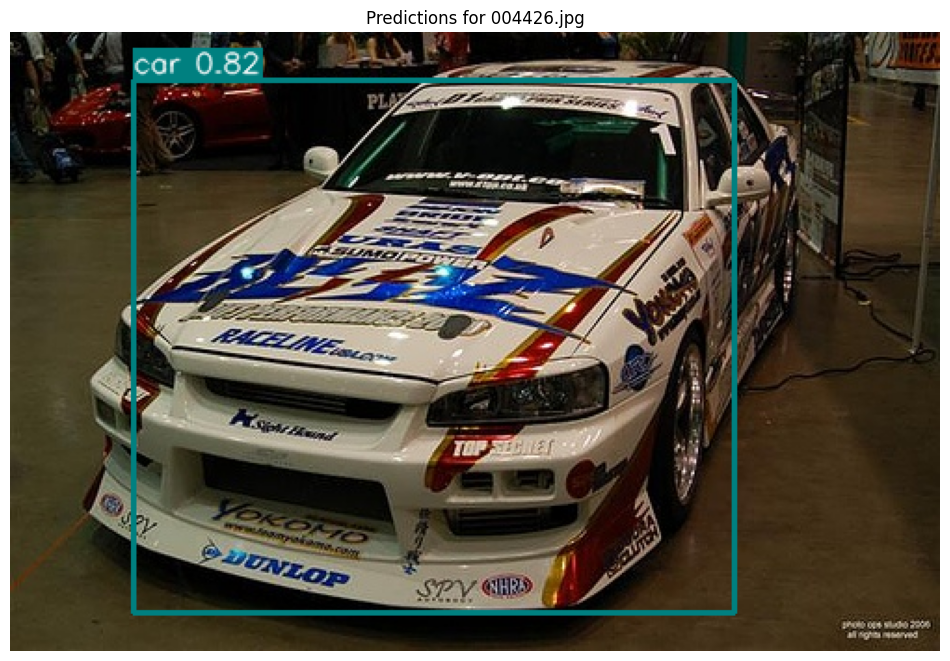

In [28]:
def load_checkpoint_for_inference(checkpoint_path: Path):
    inference_model = DetNet(
        name="resnet18",
        num_classes=len(VOC_CLASSES),
        boxes_per_cell=B,
    ).to(device)
    inference_model.load_state_dict(torch.load(checkpoint_path, map_location=device))
    inference_model.eval()
    return inference_model


checkpoint_path = run_dir / "detector_last.pth"

inference_model = load_checkpoint_for_inference(checkpoint_path)
seed_everything(SEED)  # change seed to see different images
image_name = random.choice(test_dataset.fnames)
image_bgr = cv2.imread(str(file_root_test / image_name))
image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)

# Play around with the confidence threshold and NMS IoU parameters below to see
# how they affect the predictions.
detections = predict_image(
    model=inference_model,
    image_name=image_name,
    root_img_directory=str(file_root_test),
    conf_threshold=0.5,
    nms_iou=0.5,
)

canvas = image_rgb.copy()
for det in detections:
    class_idx = VOC_CLASSES.index(det.class_name)
    color = tuple(int(c) for c in COLORS[class_idx])
    x1, y1, x2, y2 = det.box.astype(int).tolist()
    cv2.rectangle(canvas, (x1, y1), (x2, y2), color, 2)
    label = f"{det.class_name} {det.score:.2f}"
    (w, h), baseline = cv2.getTextSize(label, cv2.FONT_HERSHEY_SIMPLEX, 0.5, 1)
    text_x = x1
    text_y = max(h + 5, y1)
    cv2.rectangle(
        canvas,
        (text_x, text_y - h - baseline),
        (text_x + w, text_y),
        color,
        thickness=-1,
    )
    cv2.putText(
        canvas,
        label,
        (x1, max(15, y1 - 4)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.5,
        (255, 255, 255),
        1,
        cv2.LINE_AA,
    )

plt.figure(figsize=(12, 12))
plt.imshow(canvas)
plt.title(f"Predictions for {image_name}")
plt.axis("off")
plt.show()

## What does the detector see? Feature-map visualization
Visualize convolutional feature maps in YOLO or attention maps in DETR to better understand the models' detection behavior. What do these models "see"?

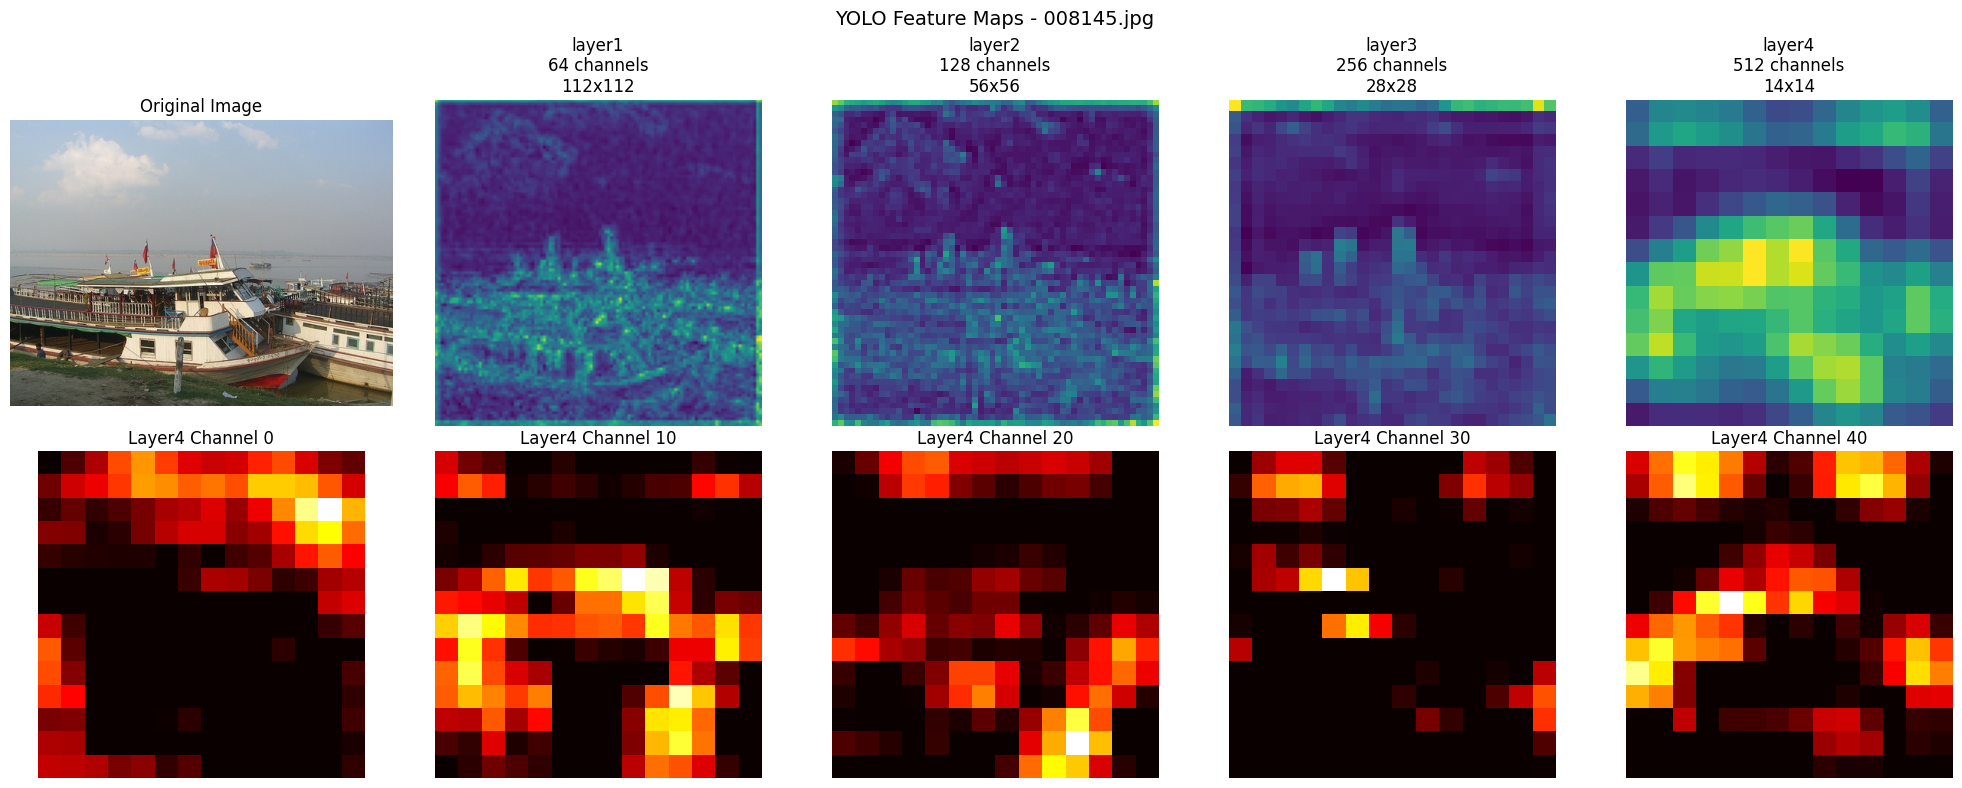

In [30]:
# Extra Credit: Visualize Convolutional Feature Maps
# This shows how the YOLO backbone processes images at different layers.
# Early layers detect low-level features (edges, textures), while deeper
# layers detect high-level semantic features (object parts, shapes).

import matplotlib.pyplot as plt
import torch
import cv2
import numpy as np

# Load trained model
model = load_checkpoint_for_inference(checkpoint_path)
model.eval()

# Select a sample image
sample_image_name = random.choice(test_dataset.fnames)
image_bgr = cv2.imread(str(file_root_test / sample_image_name))
image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)

# Preprocess the image
from src.predict import preprocess_image
img_tensor = preprocess_image(image_bgr).unsqueeze(0).to(device)

# Dictionary to store feature maps captured by hooks
features = {}

def hook_fn(name):
    """Hook function to capture intermediate feature maps"""
    def hook(module, input, output):
        features[name] = output.detach()
    return hook

# Register forward hooks at different backbone layers
# ResNet18 backbone has 4 main layers, each progressively more semantic
hooks = []
hooks.append(model.backbone.body[4].register_forward_hook(hook_fn('layer1')))  # After layer1
hooks.append(model.backbone.body[5].register_forward_hook(hook_fn('layer2')))  # After layer2
hooks.append(model.backbone.body[6].register_forward_hook(hook_fn('layer3')))  # After layer3
hooks.append(model.backbone.body[7].register_forward_hook(hook_fn('layer4')))  # After layer4

# Run forward pass to capture features
with torch.no_grad():
    _ = model(img_tensor)

# Remove hooks to avoid memory leaks
for h in hooks:
    h.remove()

# Visualize the feature maps
fig, axes = plt.subplots(2, 5, figsize=(20, 8))

# Original image
axes[0, 0].imshow(image_rgb)
axes[0, 0].set_title('Original Image')
axes[0, 0].axis('off')

# Feature maps from each layer (averaged across channels)
# Averaging shows the overall activation pattern at each layer
for idx, layer_name in enumerate(['layer1', 'layer2', 'layer3', 'layer4']):
    feat = features[layer_name][0].mean(dim=0).cpu().numpy()  # Average over channels
    axes[0, idx+1].imshow(feat, cmap='viridis')
    axes[0, idx+1].set_title(f'{layer_name}\n{features[layer_name].shape[1]} channels\n{features[layer_name].shape[2]}x{features[layer_name].shape[3]}')
    axes[0, idx+1].axis('off')

# Individual channels from layer4 (the most semantic layer)
# Different channels respond to different object features
for i in range(5):
    channel_idx = i * 10  # Channels 0, 10, 20, 30, 40
    if channel_idx < features['layer4'].shape[1]:
        feat = features['layer4'][0, channel_idx].cpu().numpy()
        axes[1, i].imshow(feat, cmap='hot')
        axes[1, i].set_title(f'Layer4 Channel {channel_idx}')
        axes[1, i].axis('off')

plt.suptitle(f'YOLO Feature Maps - {sample_image_name}', fontsize=14)
plt.tight_layout()
plt.show()

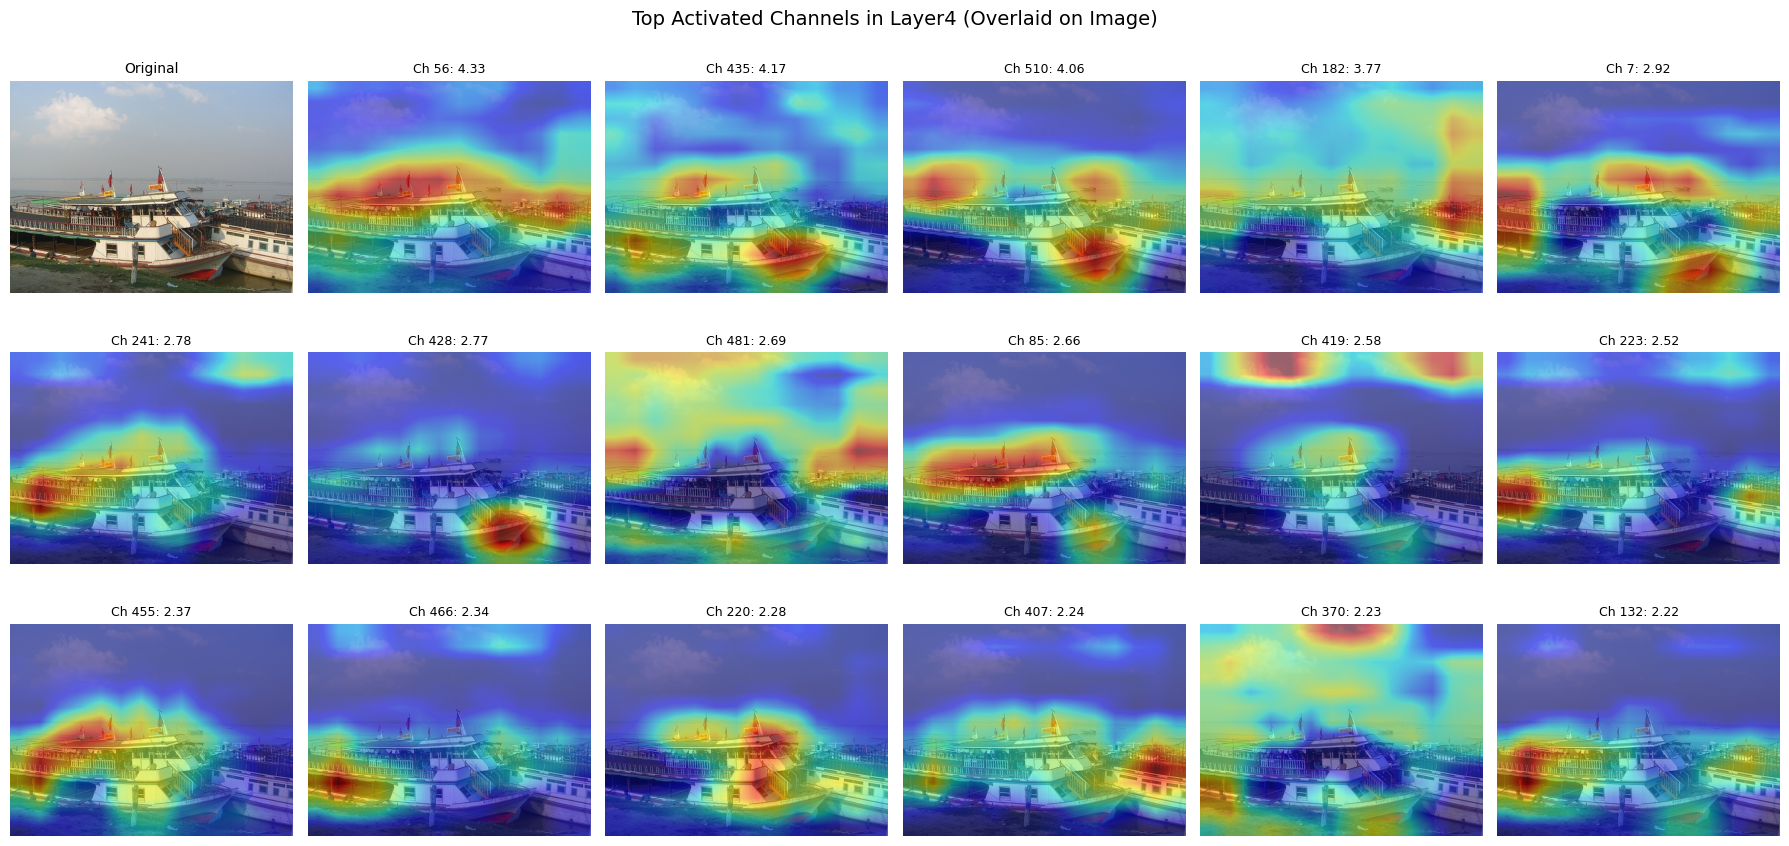

In [31]:
# Extra Credit: Channel Activation Analysis
# This visualization overlays the most activated feature channels on the original image.
# It reveals what parts of the image each channel "pays attention to".
# High activation (warm colors) indicates regions the channel finds important.

fig, axes = plt.subplots(3, 6, figsize=(18, 9))

# Original image in top-left
axes[0, 0].imshow(image_rgb)
axes[0, 0].set_title('Original', fontsize=10)
axes[0, 0].axis('off')

# Find the top 17 channels with highest mean activation
# These channels are the most "active" for this particular image
layer4_feats = features['layer4'][0]  # Shape: [C, H, W]
channel_activations = layer4_feats.mean(dim=(1, 2))  # Mean activation per channel
top_channels = torch.argsort(channel_activations, descending=True)[:17]

for idx, ch in enumerate(top_channels):
    row = (idx + 1) // 6
    col = (idx + 1) % 6

    feat = layer4_feats[ch].cpu().numpy()

    # Resize feature map to original image size for overlay
    feat_resized = cv2.resize(feat, (image_rgb.shape[1], image_rgb.shape[0]))
    # Normalize to [0, 1] for visualization
    feat_norm = (feat_resized - feat_resized.min()) / (feat_resized.max() - feat_resized.min() + 1e-8)

    # Overlay feature map on original image with transparency
    axes[row, col].imshow(image_rgb)
    axes[row, col].imshow(feat_norm, cmap='jet', alpha=0.5)
    axes[row, col].set_title(f'Ch {ch.item()}: {channel_activations[ch]:.2f}', fontsize=9)
    axes[row, col].axis('off')

plt.suptitle('Top Activated Channels in Layer4 (Overlaid on Image)', fontsize=14)
plt.tight_layout()
plt.show()

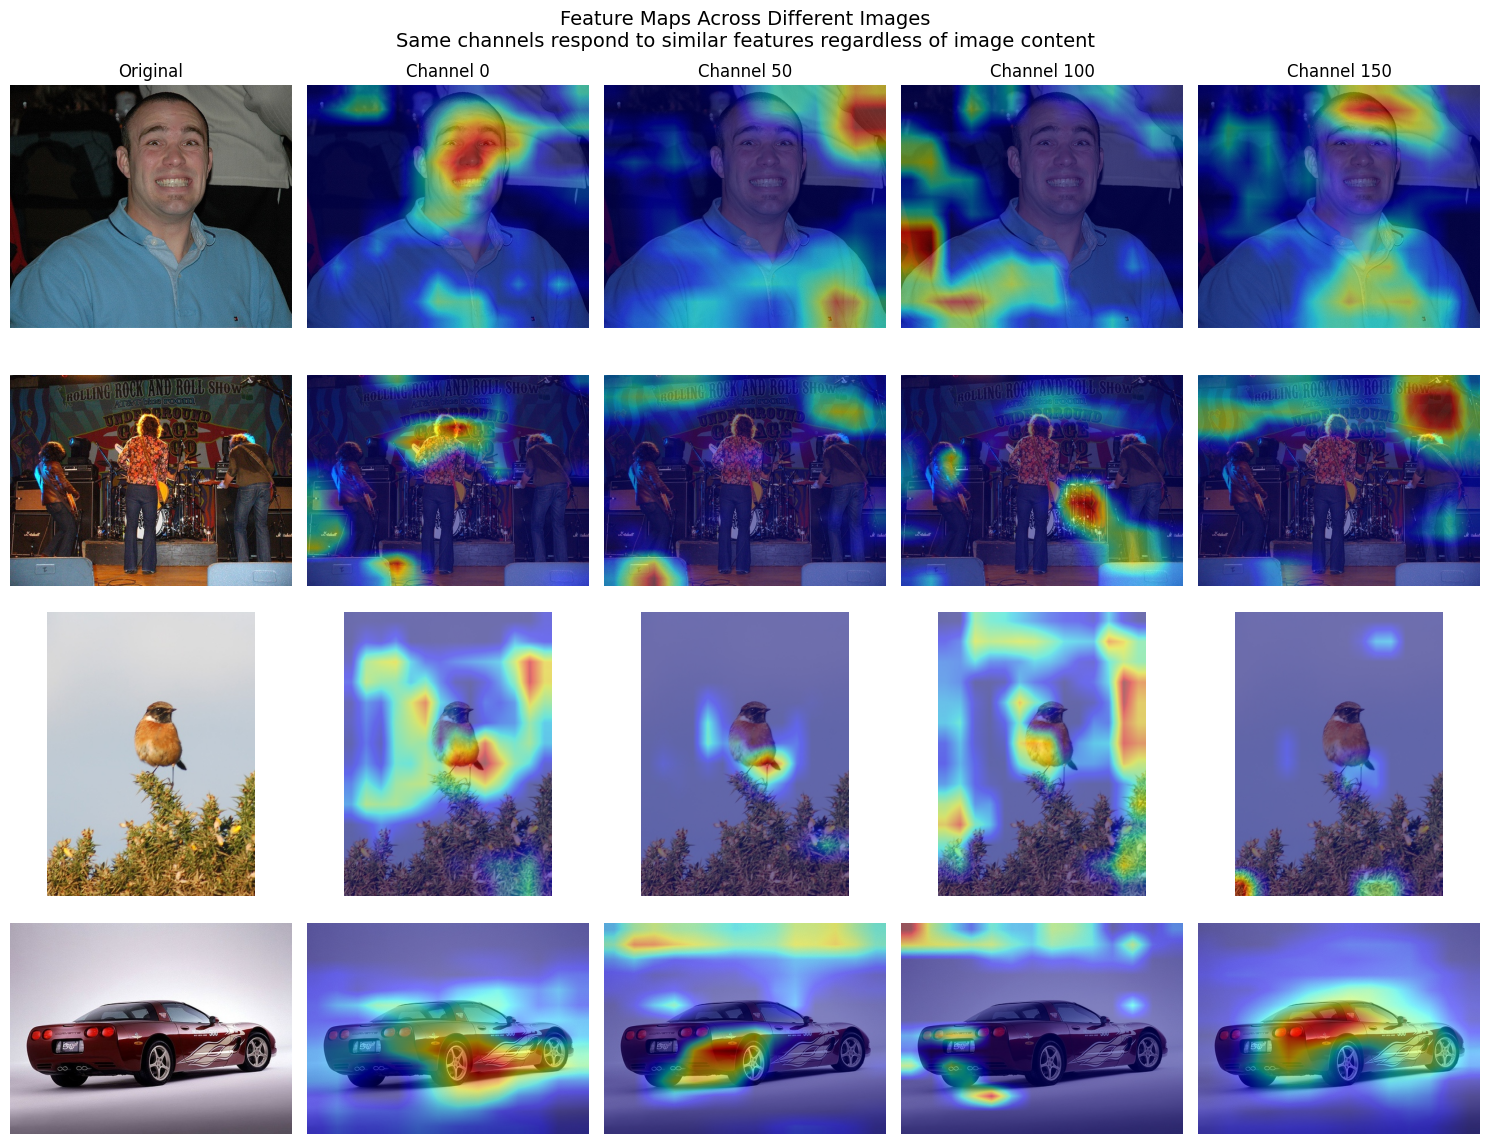

In [32]:
# Extra Credit: Feature Map Consistency Across Images
# This compares how the same channels respond to different images.
# Consistent patterns across images suggest the channel has learned
# a generalizable feature (e.g., edges, textures, object parts).

fig, axes = plt.subplots(4, 5, figsize=(15, 12))

for img_idx in range(4):
    # Select images spaced apart in the dataset
    sample_name = test_dataset.fnames[img_idx * 100]
    img_bgr = cv2.imread(str(file_root_test / sample_name))
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    img_t = preprocess_image(img_bgr).unsqueeze(0).to(device)

    # Capture layer4 features for this image
    features = {}
    hook = model.backbone.body[7].register_forward_hook(hook_fn('layer4'))
    with torch.no_grad():
        _ = model(img_t)
    hook.remove()

    # Display original image
    axes[img_idx, 0].imshow(img_rgb)
    axes[img_idx, 0].set_title('Original' if img_idx == 0 else '')
    axes[img_idx, 0].axis('off')

    # Display 4 different channels overlaid on the image
    # Using channels 0, 50, 100, 150 to see variety
    for ch_idx in range(4):
        channel = ch_idx * 50
        if channel < features['layer4'].shape[1]:
            feat = features['layer4'][0, channel].cpu().numpy()
            feat_resized = cv2.resize(feat, (img_rgb.shape[1], img_rgb.shape[0]))

            axes[img_idx, ch_idx + 1].imshow(img_rgb)
            axes[img_idx, ch_idx + 1].imshow(feat_resized, cmap='jet', alpha=0.5)
            if img_idx == 0:
                axes[img_idx, ch_idx + 1].set_title(f'Channel {channel}')
            axes[img_idx, ch_idx + 1].axis('off')

plt.suptitle('Feature Maps Across Different Images\nSame channels respond to similar features regardless of image content', fontsize=14)
plt.tight_layout()
plt.show()

## Evaluate on Test

To evaluate detection results we use mAP (mean of average precision over each class)

In [ ]:
eval_model = load_checkpoint_for_inference(checkpoint_path)
eval_results = evaluate(eval_model, print_results=True, **eval_kwargs)

print(f"\nFinal mAP: {eval_results['map']:.4f}")

Evaluating on 4950 images...

VOC Evaluation Results
Class                      AP       Prec     Recall      #Pred        #GT
-------------------------------------------------------------------------------
aeroplane              0.5977     0.1291     0.7123       1572        285
bicycle                0.7008     0.2141     0.8279       1303        337
bird                   0.5014     0.1038     0.7560       3344        459
boat                   0.3623     0.0554     0.6996       3323        263
bottle                 0.1911     0.0503     0.4776       4449        469
bus                    0.6400     0.1867     0.7746        884        213
car                    0.6159     0.1490     0.7717       6215       1200
cat                    0.7305     0.2729     0.8659       1136        358
chair                  0.2881     0.0749     0.6910       6960        754
cow                    0.4414     0.1020     0.7172       1716        244
diningtable            0.5325     0.1755     0.7039  

## Export Submission CSV

In [ ]:
def write_submission_csv(output_path: str | Path, eval_results: dict):
    output_path = Path(output_path)
    with output_path.open("w", newline="") as handle:
        writer = csv.writer(handle)
        writer.writerow(["id", "expected"])
        for idx, ap in enumerate(eval_results["aps"]):
            writer.writerow([idx, float(ap)])
    return output_path.resolve()


submission_path = write_submission_csv("my_solution_yolo.csv", eval_results)
print(f"Wrote submission file to: {submission_path}")

Wrote submission file to: my_solution_yolo.csv
